# Лабораторная: детали на конвейере

Зависимости: `%pip install torch torchvision numpy pandas pillow matplotlib`.

In [2]:
import argparse, copy, json, time, random
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from IPython.display import display

## Данные
Посмотрим на размер наборов и число объектов каждого класса. Validation используется для выбора checkpoint, test — только для получения предсказаний.

In [3]:
DATA_DIR = Path('../student')
if not (DATA_DIR / 'train.csv').is_file():
    DATA_DIR = Path('.')

train_info = pd.read_csv(DATA_DIR / 'train.csv')
val_info = pd.read_csv(DATA_DIR / 'validation.csv')
test_info = pd.read_csv(DATA_DIR / 'test.csv')

print('Train:', len(train_info), 'Validation:', len(val_info), 'Test:', len(test_info))
print('\nTrain по классам:')
display(train_info.groupby('label').size().rename('count').to_frame())
print('\nValidation по классам:')
display(val_info.groupby('label').size().rename('count').to_frame())

Train: 1880 Validation: 480 Test: 960

Train по классам:


,count
label,
0,400
1,360
2,300
3,240
4,200
5,160
6,120
7,100



Validation по классам:


,count
label,
0,60
1,60
2,60
3,60
4,60
5,60
6,60
7,60


## Метрика
Используется Macro-F1: F1 считается отдельно для каждого класса, затем значения усредняются.

In [4]:
def macro_f1(y_true, y_pred, n_classes=8):
    values = []
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    for c in range(n_classes):
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))
        values.append(2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0)
    return float(np.mean(values))

## Чтение изображений
Изображения открываются в формате RGB. Для test вместо метки возвращается `-1`.

In [5]:
class PartsDataset(Dataset):

    def __init__(self, root, csv_name, transform):
        self.root = Path(root)
        self.rows = pd.read_csv(self.root / csv_name)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image = Image.open(self.root / row['file']).convert('RGB')
        label = int(row['label']) if 'label' in self.rows else -1
        return (self.transform(image), label)

## Исходная архитектура
SmallCNN — исходная модель.

In [6]:
class SmallCNN(nn.Module):

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(1)
        )
        self.head = nn.Linear(64, 8)

    def forward(self, x):
        return self.head(self.features(x))

## Итоговая архитектура
Используется предобученная ResNet18. Все параметры замораживаются, затем размораживается `layer4`; классификатор заменяется на слой с 8 выходами.

In [7]:
class ResNet18Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = resnet18(weights=ResNet18_Weights.DEFAULT)

        for param in self.model.parameters():
            param.requires_grad = False

        for param in self.model.layer4.parameters():
            param.requires_grad = True

        self.model.fc = nn.Linear(self.model.fc.in_features, 8)

    def forward(self, x):
        return self.model(x)

    def train(self, mode=True):
        super().train(mode)
        self.model.eval()
        self.model.layer4.train(mode)
        self.model.fc.train(mode)
        return self

## Оценка без изменения весов
Функция возвращает loss, Macro-F1, accuracy, истинные метки и предсказания.

In [8]:
def evaluate(model, loader, device):
    model.eval()
    ys = []
    ps = []
    total_loss = 0
    count = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            total_loss += nn.functional.cross_entropy(logits, labels).item() * len(labels)
            count += len(labels)
            ys.extend(labels.cpu().tolist())
            ps.extend(logits.argmax(1).cpu().tolist())
    return (total_loss / count, macro_f1(ys, ps), float(np.mean(np.array(ys) == ps)), ys, ps)

## Обучение и сохранение
Для финальной модели используется предобученная ResNet18 с весами ImageNet. Обучаются последний блок `layer4` и классификатор `fc`, остальные слои заморожены.

Перед подачей в модель изображения увеличиваются до 128 × 128. Во время обучения дополнительно применяются небольшие повороты, горизонтальное отражение и изменение яркости и контраста. Для validation и test используются только изменение размера и нормализация.

После каждой эпохи модель оценивается на validation. Сохраняется checkpoint с наибольшим Macro-F1. В результате записываются веса модели, история обучения, предсказания на validation и итоговый submission.csv.

In [9]:
def run(data='.', out='runs/baseline', epochs=12, seed=17):
    if epochs < 1:
        raise ValueError('epochs must be positive')
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(2)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    train_ops = [
        transforms.Resize(128),
        transforms.RandomRotation(10),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(brightness=0.15, contrast=0.15)
    ]
    eval_ops = [
        transforms.Resize(128),
    ]
    final_ops = [
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        )
    ]
    train_data = PartsDataset(data, 'train.csv', transforms.Compose(train_ops + final_ops))
    val_data = PartsDataset(data, 'validation.csv', transforms.Compose(eval_ops + final_ops))
    test_data = PartsDataset(data, 'test.csv', transforms.Compose(eval_ops + final_ops))
    generator = torch.Generator().manual_seed(seed)
    tl = DataLoader(train_data, batch_size=64, shuffle=True, num_workers=0, generator=generator)
    vl = DataLoader(val_data, batch_size=64, shuffle=False, num_workers=0)
    model = ResNet18Classifier().to(device)

    optimizer = torch.optim.AdamW(
        [
            {'params': model.model.layer4.parameters(), 'lr': 0.0001},
            {'params': model.model.fc.parameters(), 'lr': 0.001}
        ],
        weight_decay=0.0001
    )
    class_weights = None
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    best = -1
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total = 0
        for images, labels in tl:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)
            total += len(labels)
        vl_loss, f1, acc, ys, ps = evaluate(model, vl, device)
        history.append({'epoch': epoch + 1, 'train_loss': total_loss / total, 'val_loss': vl_loss, 'val_macro_f1': f1, 'val_accuracy': acc})
        if f1 > best:
            best = f1
            state = copy.deepcopy(model.state_dict())
        print(f'{epoch + 1:02d}: loss {total_loss / total:.3f}; val F1 {f1:.3f}; acc {acc:.3f}', flush=True)
    model.load_state_dict(state)
    torch.save(model.state_dict(), out / 'model.pt')
    pd.DataFrame(history).to_csv(out / 'history.csv', index=False)
    _, f1, acc, ys, ps = evaluate(model, vl, device)
    pd.DataFrame({'id': val_data.rows.id, 'label': ys, 'prediction': ps}).to_csv(out / 'validation_predictions.csv', index=False)
    model.eval()
    pred = []
    with torch.no_grad():
        for images, labels in DataLoader(test_data, batch_size=64, shuffle=False, num_workers=0):
            pred.extend(model(images.to(device)).argmax(1).cpu().tolist())
    pd.DataFrame({'id': test_data.rows.id, 'label': pred}).to_csv(out / 'submission.csv', index=False)
    result = {'seed': seed, 'epochs': epochs, 'best_val_macro_f1': f1, 'val_accuracy': acc, 'parameters': sum((p.numel() for p in model.parameters())), 'seconds': time.time() - start}
    (out / 'results.json').write_text(json.dumps(result, indent=2))
    print(result, flush=True)

## Финальный запуск
Seed=42, 40 эпох. Файлы выбранного запуска сохраняются в текущую папку.

In [17]:
run(data=DATA_DIR, out='.', epochs=40, seed=42)

01: loss 0.551; val F1 0.935; acc 0.935
02: loss 0.133; val F1 0.971; acc 0.971
03: loss 0.082; val F1 0.967; acc 0.967
04: loss 0.058; val F1 0.967; acc 0.967
05: loss 0.054; val F1 0.964; acc 0.965
06: loss 0.045; val F1 0.983; acc 0.983
07: loss 0.031; val F1 0.987; acc 0.988
08: loss 0.024; val F1 0.971; acc 0.971
09: loss 0.023; val F1 0.981; acc 0.981
10: loss 0.043; val F1 0.983; acc 0.983
11: loss 0.017; val F1 0.983; acc 0.983
12: loss 0.013; val F1 0.987; acc 0.988
13: loss 0.016; val F1 0.990; acc 0.990
14: loss 0.032; val F1 0.938; acc 0.940
15: loss 0.022; val F1 0.994; acc 0.994
16: loss 0.018; val F1 0.981; acc 0.981
17: loss 0.016; val F1 0.977; acc 0.977
18: loss 0.011; val F1 0.990; acc 0.990
19: loss 0.044; val F1 0.994; acc 0.994
20: loss 0.024; val F1 0.990; acc 0.990
21: loss 0.014; val F1 0.990; acc 0.990
22: loss 0.015; val F1 0.992; acc 0.992
23: loss 0.007; val F1 0.994; acc 0.994
24: loss 0.009; val F1 0.987; acc 0.988
25: loss 0.006; val F1 0.994; acc 0.994


## Результаты экспериментов
В таблицу включены baseline, изменения SmallCNN и последовательные варианты ResNet18 до финального изменения размера входа.

**Baseline–EXP03.** Начал с исходной SmallCNN. В EXP01 изменил расположение pooling, чтобы сохранить больше информации об изображениях. В EXP02 добавил аугментации, а в EXP03 уменьшил learning rate с 0.002 до 0.001. Все три изменения почти не повлияли на качество: Macro-F1 остался около 0.48.

**EXP04–EXP05.** Перешёл на предобученную ResNet18. Сначала заморозил backbone и обучал только классификатор. За 12 эпох Macro-F1 вырос до 0.8704. Повтор с другим seed показал результат 0.8620.

**EXP06.** Увеличил обучение до 40 эпох. Macro-F1 повысился до 0.9144. Это показало, что модели требуется больше времени для обучения классификатора.

**EXP07–EXP08.** Разморозил последний блок ResNet18 (`layer4`), чтобы модель могла дополнительно адаптировать признаки под изображения деталей. Для `layer4` и `fc` использовал разные learning rate. Результат вырос до 0.9771, а повтор с seed=42 показал 0.9833.

**EXP10.** Изменил размер входных изображений с 64 × 64 на 128 × 128. При 12 эпохах Macro-F1 составил 0.9875. После увеличения обучения до 40 эпох результат достиг 0.9958. Повтор с seed=17 показал практически такое же качество.

In [11]:
experiments = [
    ['Baseline', 'SmallCNN, исходные настройки', 17, 12, 0.4824777118, 0.481250, 24104, 20.0],
    ['EXP01', 'Изменение pooling в SmallCNN', 17, 12, 0.4816893063, 0.479167, 35672, 49.0],
    ['EXP02', 'Аугментации для SmallCNN', 17, 12, 0.4830948457, 0.481250, 24104, 21.5],
    ['EXP03', 'Изменение learning rate SmallCNN', 17, 12, 0.4834821989, 0.483333, 24104, 21.3],
    ['EXP04', 'ResNet18, обучение классификатора', 17, 12, 0.8703679835, 0.870833, 11180616, 109.7],
    ['EXP05', 'Повтор EXP04 с другим seed', 42, 12, 0.8619689918, 0.862500, 11180616, 112.3],
    ['EXP06', 'ResNet18, замороженная backbone, 40 эпох', 17, 40, 0.9144113190, 0.914583, 11180616, 750.1],
    ['EXP07', 'Разморозка layer4 и обучение fc', 17, 40, 0.9770785577, 0.977083, 11180616, 553.9],
    ['EXP08', 'Повтор EXP07 с другим seed', 42, 40, 0.9833194290, 0.983333, 11180616, 599.8],
    ['EXP10, 12 эпох', 'Размер входа 128 × 128', 42, 12, 0.9874997106, 0.987500, 11180616, 347.5],
    ['EXP10, повтор', 'Та же конфигурация, другой seed', 17, 40, 0.9958330440, 0.995833, 11180616, 1943.6],
    ['EXP10, 40 эпох', 'Финальная конфигурация, 128 × 128', 42, 40, 0.9958321756, 0.995833, 11180616, 1909.8],
]
experiment_table = pd.DataFrame(
    experiments,
    columns=['Опыт', 'Изменение', 'Seed', 'Эпохи', 'Validation Macro-F1', 'Accuracy', 'Параметры', 'Время, с']
)
display(experiment_table.style.format({
    'Validation Macro-F1': '{:.4f}', 'Accuracy': '{:.4f}',
    'Параметры': '{:,.0f}', 'Время, с': '{:.1f}'
}))

,Опыт,Изменение,Seed,Эпохи,Validation Macro-F1,Accuracy,Параметры,"Время, с"
0,Baseline,"SmallCNN, исходные настройки",17,12,0.4825,0.4813,"24,104",20.0
1,EXP01,Изменение pooling в SmallCNN,17,12,0.4817,0.4792,"35,672",49.0
2,EXP02,Аугментации для SmallCNN,17,12,0.4831,0.4813,"24,104",21.5
3,EXP03,Изменение learning rate SmallCNN,17,12,0.4835,0.4833,"24,104",21.3
4,EXP04,"ResNet18, обучение классификатора",17,12,0.8704,0.8708,"11,180,616",109.7
5,EXP05,Повтор EXP04 с другим seed,42,12,0.8620,0.8625,"11,180,616",112.3
6,EXP06,"ResNet18, замороженная backbone, 40 эпох",17,40,0.9144,0.9146,"11,180,616",750.1
7,EXP07,Разморозка layer4 и обучение fc,17,40,0.9771,0.9771,"11,180,616",553.9
8,EXP08,Повтор EXP07 с другим seed,42,40,0.9833,0.9833,"11,180,616",599.8
9,"EXP10, 12 эпох",Размер входа 128 × 128,42,12,0.9875,0.9875,"11,180,616",347.5


### Наблюдения
- Изменения архитектуры, аугментаций и learning rate практически не улучшили исходную SmallCNN. Её Macro-F1 оставался около 0.48.
- Использование предобученной ResNet18 дало заметный прирост качества даже при обучении только классификатора.
- Увеличение числа эпох с 12 до 40 позволило улучшить результат до 0.9144.
- Разморозка `layer4` дала дополнительный прирост: Macro-F1 достиг 0.9771–0.9833.
- Увеличение входного разрешения с 64 × 64 до 128 × 128 при одинаковых seed и числе эпох повысило Macro-F1 с 0.9833 до 0.9958.
- Повтор финального эксперимента с другим seed дал практически такой же результат. Это показывает стабильность выбранной конфигурации в проведённых запусках.

## Графики
Покажем обучение финальной модели и, если сохранена история baseline, сравним validation-кривые.

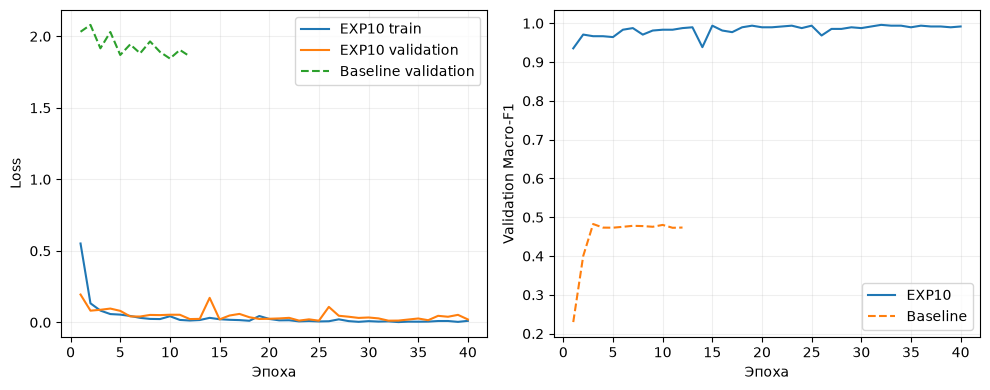

Лучшая эпоха: 32
Лучший validation Macro-F1: 0.995832


In [12]:
history = pd.read_csv('history.csv')
baseline_history_path = DATA_DIR / 'runs' / 'baseline' / 'history.csv'

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.epoch, history.train_loss, label='EXP10 train')
axes[0].plot(history.epoch, history.val_loss, label='EXP10 validation')
if baseline_history_path.is_file():
    baseline_history = pd.read_csv(baseline_history_path)
    axes[0].plot(baseline_history.epoch, baseline_history.val_loss, '--', label='Baseline validation')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.epoch, history.val_macro_f1, label='EXP10')
if baseline_history_path.is_file():
    axes[1].plot(baseline_history.epoch, baseline_history.val_macro_f1, '--', label='Baseline')
axes[1].set_ylabel('Validation Macro-F1')
axes[1].legend()

for ax in axes:
    ax.set_xlabel('Эпоха')
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

best_row = history.loc[history.val_macro_f1.idxmax()]
print('Лучшая эпоха:', int(best_row.epoch))
print('Лучший validation Macro-F1:', round(float(best_row.val_macro_f1), 6))

## Анализ ошибок
Матрица ошибок и метрики по классам рассчитываются по сохранённым предсказаниям validation.

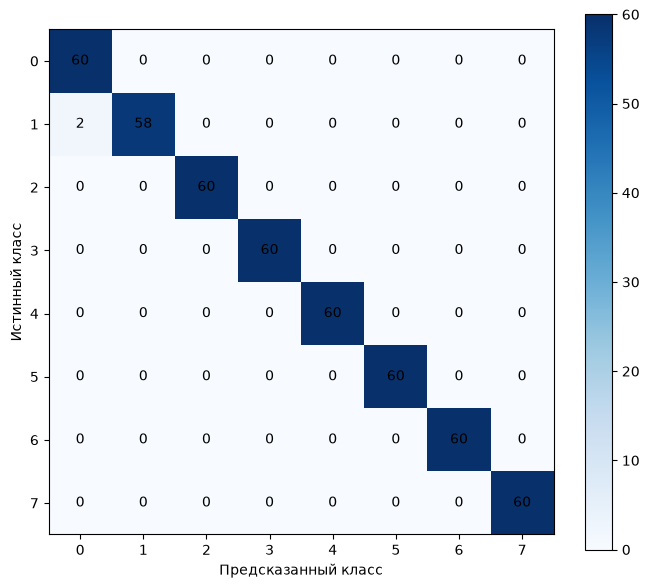

In [13]:
validation_predictions = pd.read_csv('validation_predictions.csv')
y_true = validation_predictions['label'].to_numpy()
y_pred = validation_predictions['prediction'].to_numpy()
n_classes = 8

confusion = np.zeros((n_classes, n_classes), dtype=int)
for true_label, predicted_label in zip(y_true, y_pred):
    confusion[int(true_label), int(predicted_label)] += 1

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(confusion, cmap='Blues')
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
for i in range(n_classes):
    for j in range(n_classes):
        ax.text(j, i, confusion[i, j], ha='center', va='center')
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

In [14]:
class_metrics = []
for c in range(n_classes):
    tp = confusion[c, c]
    fp = confusion[:, c].sum() - tp
    fn = confusion[c, :].sum() - tp
    support = confusion[c, :].sum()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    class_metrics.append([c, precision, recall, f1, support])

class_metrics = pd.DataFrame(class_metrics, columns=['Класс', 'Precision', 'Recall', 'F1', 'Объектов'])
display(class_metrics.style.format({'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1': '{:.3f}'}))
print('Ошибок на validation:', int((y_true != y_pred).sum()), 'из', len(y_true))
print('Macro-F1:', round(macro_f1(y_true, y_pred), 6))

,Класс,Precision,Recall,F1,Объектов
0,0,0.968,1.000,0.984,60
1,1,1.000,0.967,0.983,60
2,2,1.000,1.000,1.000,60
3,3,1.000,1.000,1.000,60
4,4,1.000,1.000,1.000,60
5,5,1.000,1.000,1.000,60
6,6,1.000,1.000,1.000,60
7,7,1.000,1.000,1.000,60


Ошибок на validation: 2 из 480
Macro-F1: 0.995832


### Примеры ошибок
Посмотрим на изображения, для которых предсказанный класс не совпал с истинным.

Найдено ошибок: 2


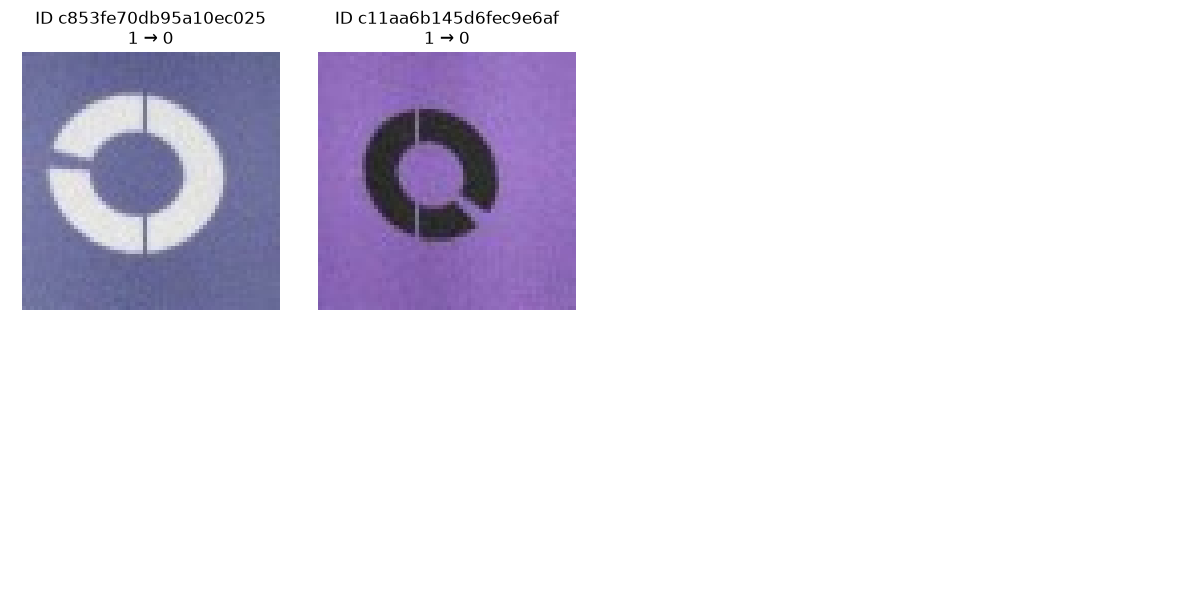

In [15]:
errors = val_info.merge(validation_predictions, on='id', suffixes=('', '_pred'))
errors = errors[errors['label'] != errors['prediction']]
print('Найдено ошибок:', len(errors))

if len(errors) > 0:
    n_show = min(8, len(errors))
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax in axes.flat:
        ax.axis('off')
    for ax, (_, row) in zip(axes.flat, errors.head(n_show).iterrows()):
        image = Image.open(DATA_DIR / row['file']).convert('RGB')
        ax.imshow(image)
        ax.set_title(f"ID {row['id']}\n{int(row['label'])} → {int(row['prediction'])}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Ошибочных предсказаний нет.')

## Финальная модель и повторное предсказание

- Архитектура: ResNet18, предобученные веса ImageNet;
- Размер входа: 128 × 128 RGB.
- Batch size — 64, seed — 42, максимум — 40 эпох.
- Число параметров — 11 180 616 (ограничение задания — 12 млн).

Команда обучения из папки с `train.py`:

```bash
python train.py --data ../student --out . --epochs 40 --seed 42
```

Получение предсказаний без обучения:

```bash
python predict.py --data ../student --weights model.pt --output submission.csv
```

In [16]:
with open('results.json', 'r') as f:
    results = json.load(f)

print('Seed:', results['seed'])
print('Эпох:', results['epochs'])
print('Validation Macro-F1:', f"{results['best_val_macro_f1']:.6f}")
print('Validation accuracy:', f"{results['val_accuracy']:.6f}")
print('Параметров:', f"{results['parameters']:,}".replace(',', ' '))
print('Время обучения, с:', round(results['seconds'], 1))

print('\nВерсии библиотек:')
print('Python / PyTorch:', torch.__version__)
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)

Seed: 42
Эпох: 40
Validation Macro-F1: 0.995832
Validation accuracy: 0.995833
Параметров: 11 180 616
Время обучения, с: 1909.8

Версии библиотек:
Python / PyTorch: 2.15.0
NumPy: 2.5.5
Pandas: 3.1.1


## Вывод

В ходе работы были проверены разные варианты архитектуры и настроек обучения для классификации деталей на конвейере.

Исходная SmallCNN показала Macro-F1 около 0.48. Изменения её архитектуры, аугментаций и learning rate практически не улучшили результат. Значительный прирост качества удалось получить после перехода на предобученную ResNet18.

Дальнейшее дообучение последнего блока сети и увеличение входного разрешения до 128 × 128 позволили довести validation Macro-F1 до 0.9958. Accuracy составила 0.9958, то есть модель правильно классифицировала 479 из 480 изображений validation.

Финальной выбрана ResNet18 с предобученными весами ImageNet, дообучаемыми `layer4` и `fc`, размером входа 128 × 128 и 40 эпохами обучения. Модель содержит 11 180 616 параметров, что соответствует ограничению в 12 млн. Время финального запуска составило около 1909.8 секунды.

Повторный запуск с другим seed показал практически такой же результат. Поэтому выбранная конфигурация была использована для получения финальных предсказаний.

Для сдачи приложены `model.pt`, `submission.csv`, `history.csv`, `predict.py`, `requirements.txt` и `README.txt`.